In [1]:
import pandas as pd 
import numpy as np

/home/md88vyxi/.local/lib/python3.6/site-packages/matplotlib/backends/backend_agg.py:238: RuntimeWarning: Glyph 20803 missing from current font.
  font.set_text(s, 0.0, flags=flags)
/home/md88vyxi/.local/lib/python3.6/site-packages/matplotlib/backends/backend_agg.py:238: RuntimeWarning: Glyph 32032 missing from current font.
  font.set_text(s, 0.0, flags=flags)
/home/md88vyxi/.local/lib/python3.6/site-packages/matplotlib/backends/backend_agg.py:238: RuntimeWarning: Glyph 20116 missing from current font.
  font.set_text(s, 0.0, flags=flags)
/home/md88vyxi/.local/lib/python3.6/site-packages/matplotlib/backends/backend_agg.py:238: RuntimeWarning: Glyph 36793 missing from current font.
  font.set_text(s, 0.0, flags=flags)
/home/md88vyxi/.local/lib/python3.6/site-packages/matplotlib/backends/backend_agg.py:238: RuntimeWarning: Glyph 24418 missing from current font.
  font.set_text(s, 0.0, flags=flags)
/home/md88vyxi/.local/lib/python3.6/site-packages/matplotlib/backends/backend_agg.py:201: 

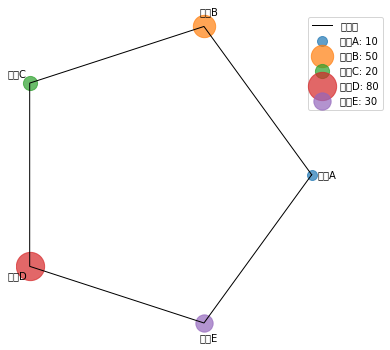

In [2]:
import matplotlib.pyplot as plt
import numpy as np

# 五边形的顶点数和元素
elements = ['元素A', '元素B', '元素C', '元素D', '元素E']
values = [10, 50, 20, 80, 30]  # 每种元素的含量

# 计算五边形顶点的角度（用极坐标）
angles = np.linspace(0, 2 * np.pi, len(elements), endpoint=False).tolist()

# 添加第一个点闭合五边形
angles += angles[:1]
values += values[:1]

# 五边形顶点的 x 和 y 坐标
x = [np.cos(angle) for angle in angles]
y = [np.sin(angle) for angle in angles]

# 创建图形
fig, ax = plt.subplots(figsize=(6, 6))
ax.set_aspect('equal')

# 画五边形的边
ax.plot(x, y, 'k-', lw=1, label='五边形')

# 在顶点用点表示元素的含量
for i, (xi, yi) in enumerate(zip(x[:-1], y[:-1])):  # 忽略闭合点
    ax.scatter(xi, yi, s=values[i]*10, label=f'{elements[i]}: {values[i]}', alpha=0.7)

# 添加顶点的标签
for i, (xi, yi) in enumerate(zip(x[:-1], y[:-1])):
    ax.text(xi * 1.1, yi * 1.1, elements[i], ha='center', va='center', fontsize=10)

# 美化图形
ax.set_xticks([])
ax.set_yticks([])
ax.axis('off')
ax.legend(loc='upper right', bbox_to_anchor=(1.2, 1))

plt.show()


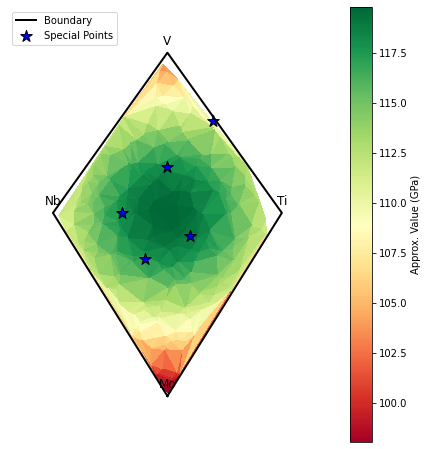

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.tri import Triangulation

# 五边形顶点 (手动定义)
vertices = np.array([
    [0.5, 0.0],   # Mo
    [1.0, 0.8],   # Ti
    [0.5, 1.5],   # V
    [0.0, 0.8],   # Nb
    [0.5, 0.0]    # W (闭合)
])

# 定义网格数据点 (示例)
x = np.random.uniform(0.0, 1.0, 500)
y = np.random.uniform(0.0, 1.5, 500)
z = 70 + 50 * np.exp(-(x - 0.5)**2 - (y - 0.8)**2)  # 模拟属性值 (类似于GPa)

# 创建五边形范围内的过滤条件
from matplotlib.path import Path
polygon_path = Path(vertices)
mask = polygon_path.contains_points(np.vstack((x, y)).T)

# 过滤数据到五边形范围
x, y, z = x[mask], y[mask], z[mask]

# 绘制五边形填充图
fig, ax = plt.subplots(figsize=(8, 8))
tri = Triangulation(x, y)
tpc = ax.tripcolor(tri, z, shading="flat", cmap="RdYlGn")
plt.colorbar(tpc, label="Approx. Value (GPa)")

# 绘制五边形边界
ax.plot(vertices[:, 0], vertices[:, 1], 'k-', lw=2, label="Boundary")

# 添加星形标记点 (特定数据点)
stars_x = [0.4, 0.6, 0.5, 0.3, 0.7]  # 示例数据点坐标
stars_y = [0.6, 0.7, 1.0, 0.8, 1.2]
ax.scatter(stars_x, stars_y, color="blue", edgecolors="black", marker="*", s=150, label="Special Points")

# 添加顶点标注
labels = ["Mo", "Ti", "V", "Nb", "W"]
for i, (xv, yv) in enumerate(vertices[:-1]):
    ax.text(xv, yv + 0.05, labels[i], ha="center", va="center", fontsize=12)

# 美化图形
ax.set_aspect('equal')
ax.set_xlim(-0.2, 1.2)
ax.set_ylim(-0.2, 1.7)
ax.axis('off')
ax.legend(loc="upper left")

plt.show()


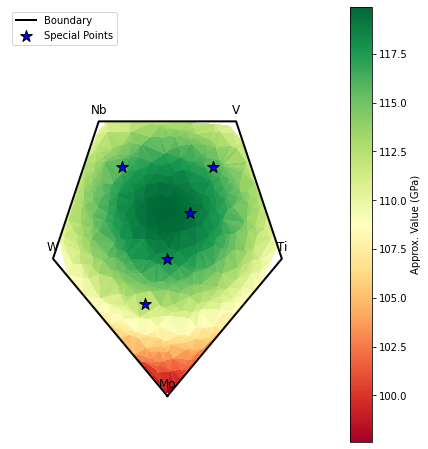

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.tri import Triangulation

# 五边形顶点 (手动定义)
vertices = np.array([
    [0.5, 0.0],   # Mo
    [1.0, 0.6],   # Ti
    [0.8, 1.2],   # V
    [0.2, 1.2],   # Nb
    [0.0, 0.6],   # W
    [0.5, 0.0]    # 回到Mo (闭合)
])

# 定义网格数据点 (随机生成)
x = np.random.uniform(0.0, 1.0, 1000)
y = np.random.uniform(0.0, 1.5, 1000)
z = 70 + 50 * np.exp(-(x - 0.5)**2 - (y - 0.8)**2)  # 模拟属性值 (如GPa)

# 创建五边形范围内的过滤条件
from matplotlib.path import Path
polygon_path = Path(vertices)
mask = polygon_path.contains_points(np.vstack((x, y)).T)

# 过滤数据到五边形范围
x, y, z = x[mask], y[mask], z[mask]

# 绘制五边形填充图
fig, ax = plt.subplots(figsize=(8, 8))
tri = Triangulation(x, y)
tpc = ax.tripcolor(tri, z, shading="flat", cmap="RdYlGn")
plt.colorbar(tpc, label="Approx. Value (GPa)")

# 绘制五边形边界
ax.plot(vertices[:, 0], vertices[:, 1], 'k-', lw=2, label="Boundary")

# 添加星形标记点 (特定数据点)
stars_x = [0.4, 0.6, 0.7, 0.3, 0.5]  # 示例数据点坐标
stars_y = [0.4, 0.8, 1.0, 1.0, 0.6]
ax.scatter(stars_x, stars_y, color="blue", edgecolors="black", marker="*", s=150, label="Special Points")

# 添加顶点标注
labels = ["Mo", "Ti", "V", "Nb", "W"]
for i, (xv, yv) in enumerate(vertices[:-1]):
    ax.text(xv, yv + 0.05, labels[i], ha="center", va="center", fontsize=12)

# 美化图形
ax.set_aspect('equal')
ax.set_xlim(-0.2, 1.2)
ax.set_ylim(-0.2, 1.7)
ax.axis('off')
ax.legend(loc="upper left")

plt.show()
